# Q6: Tracking with Segment Anything 2 (Extra Credit, 15 points)

In this notebook you will track the **same objects, starting from the same initial rectangles** as in `LucasKanade.ipynb` (Q2.3), but with a modern pre-trained video segmentation model, [SAM 2](https://ai.meta.com/sam2/), instead of Lucas-Kanade. You only run the model (inference); there is no training. Section 6.1 of the handout explains how the model works; please refer to the handout for the detailed questions.

**Before you start:** switch to a GPU runtime (`Runtime -> Change runtime type -> T4 GPU`). The notebook also runs on CPU, but the car sequence then takes roughly 15-20 minutes instead of about one.

After you finish the assignment, **remember to run all cells** and save the notebook to your local machine as a PDF for gradescope submission.

# Initialization

SAM 2 video support was added to Hugging Face `transformers` in version 4.56, so we first make sure a recent enough version is installed (this is a no-op on a recent Colab image).

In [1]:
!pip install -q "transformers>=4.56" accelerate

In [2]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from tqdm import tqdm

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on:', device)
if device == 'cpu':
    print('WARNING: no GPU found. Tracking will work but be slow. '
          'Use Runtime -> Change runtime type -> T4 GPU.')

Running on: cuda


# Download data

Same two sequences as in Q2.3.

In [3]:
# Download the data
if not os.path.exists('/content/carseq.npy'):
    !wget https://www.cs.cmu.edu/~deva/data/carseq.npy -O /content/carseq.npy
if not os.path.exists('/content/girlseq.npy'):
    !wget https://www.cs.cmu.edu/~deva/data/girlseq.npy -O /content/girlseq.npy

--2026-10-02 19:36:27--  https://www.cs.cmu.edu/~deva/data/carseq.npy
Resolving www.cs.cmu.edu (www.cs.cmu.edu)... 128.2.42.95
Connecting to www.cs.cmu.edu (www.cs.cmu.edu)|128.2.42.95|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 254976128 (243M)
Saving to: ‘/content/carseq.npy’

/content/carseq.npy 100%[===================>] 243.16M  1.37MB/s    in 3m 4s   

2026-10-02 19:39:32 (1.32 MB/s) - ‘/content/carseq.npy’ saved [254976128/254976128]

--2026-10-02 19:39:32--  https://www.cs.cmu.edu/~deva/data/girlseq.npy
Resolving www.cs.cmu.edu (www.cs.cmu.edu)... 128.2.42.95
Connecting to www.cs.cmu.edu (www.cs.cmu.edu)|128.2.42.95|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 27648128 (26M)
Saving to: ‘/content/girlseq.npy’

/content/girlseq.np 100%[===================>]  26.37M  1.38MB/s    in 19s     

2026-10-02 19:39:53 (1.36 MB/s) - ‘/content/girlseq.npy’ saved [27648128/27648128]



# Helper functions

`draw_rect` is copied from `LucasKanade.ipynb`. `visualize_masks` paints the predicted mask on top of each frame, and `to_rgb_frame` turns a grayscale frame into the 3-channel image SAM 2 expects.

In [4]:
def draw_rect(rect, color):
    w = rect[2] - rect[0]
    h = rect[3] - rect[1]
    plt.gca().add_patch(patches.Rectangle((rect[0], rect[1]), w, h, linewidth=1, edgecolor=color, facecolor='none'))


def visualize_masks(seq, masks, frames, prompt_rect=None):
    '''
    Show the frames listed in `frames` with the SAM 2 mask painted in translucent blue.
    If prompt_rect is given, it is drawn in red on frame 0 (it is the box prompt).
    '''
    plt.figure(figsize=(15, 15))
    for i, idx in enumerate(frames):
        plt.subplot(1, len(frames), i + 1)
        plt.imshow(seq[:, :, idx], cmap='gray')
        overlay = np.zeros(masks[idx].shape + (4,))
        overlay[masks[idx]] = [0.1, 0.4, 1.0, 0.45]   # RGBA
        plt.imshow(overlay)
        title = f'frame {idx}'
        if prompt_rect is not None and idx == 0:
            draw_rect(prompt_rect, 'r')
            title += '\n(red = box prompt)'
        plt.axis('off')
        plt.title(title)


def to_rgb_frame(gray):
    '''
    Convert one grayscale frame (H, W) from the .npy sequences into the (H, W, 3) uint8 RGB
    image that SAM 2 expects. Works for both [0, 1] float and [0, 255] inputs.
    '''
    g = np.asarray(gray, dtype=np.float64)
    if g.max() <= 1.0:
        g = g * 255.0
    g = np.clip(np.round(g), 0, 255).astype(np.uint8)
    return np.stack([g, g, g], axis=-1)

# Q6.2: Tracking with SAM 2 (15 points)

Make sure to comment your code and use proper names for your variables.

We load the smallest SAM 2.1 checkpoint (`hiera-tiny`, about 39M parameters). It is plenty for 240x320 frames. If you are curious, `facebook/sam2.1-hiera-small` is a bit more accurate and a bit slower; larger checkpoints are not needed here.

In [5]:
from transformers import Sam2VideoModel, Sam2VideoProcessor

MODEL_ID = 'facebook/sam2.1-hiera-tiny'

processor = Sam2VideoProcessor.from_pretrained(MODEL_ID)
model = Sam2VideoModel.from_pretrained(MODEL_ID).to(device)
model.eval()
print(f'{MODEL_ID}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters')

processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/705 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

[transformers] `memory_attention_rope_theta` is deprecated and will be removed in v5.0. Use `rope_parameters['rope_theta']` instead.


model.safetensors: reconstructing file:   0%|          |  0.00B /  156MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/469 [00:00<?, ?it/s]

facebook/sam2.1-hiera-tiny: 39.0M parameters


## How the streaming API works

SAM 2 keeps everything it remembers about the video (the prompt, and the features and masks of the recent frames) inside an **inference session** object. We will use it in *streaming* mode, which means we hand it one frame at a time, exactly like the loop over frames in `TrackSequence` (Q2.3). The four calls you need are:

```python
# once, before the loop
inference_session = processor.init_video_session(inference_device=device)

# every frame: resize/normalize the frame for the network
inputs = processor(images=frame_rgb, return_tensors='pt').to(device)

# first frame only: tell the model which object to track, using our rect as a box prompt
processor.add_inputs_to_inference_session(
    inference_session=inference_session,
    frame_idx=0,
    obj_ids=1,                                    # any integer id for the object
    input_boxes=[[[x1, y1, x2, y2]]],             # shape: [batch][object][4]
    original_size=inputs.original_sizes[0],       # required in streaming mode
)

# every frame: run the network. This also writes the frame into the memory bank.
out = model(inference_session=inference_session, frame=inputs.pixel_values[0])

# every frame: out.pred_masks holds low-resolution per-pixel scores (logits).
# post_process_masks upsamples them to the frame size and thresholds them at 0.
masks = processor.post_process_masks([out.pred_masks], original_sizes=inputs.original_sizes, binarize=True)[0]
# masks has shape (num_objects, 1, H, W); we track one object, so masks[0, 0] is our (H, W) binary mask
```

Two things to notice: there is no `num_iters` or `threshold`, because nothing is optimized at test time, and the box is only given in frame 0, so every later frame is tracked purely from memory.

In [6]:
def TrackSequenceSAM(seq, rect, model, processor, obj_id=1, show_progress=True):
    '''
    :param seq       : (H, W, T), sequence of grayscale frames (same format as Q2)
    :param rect      : (4,), [x1 y1 x2 y2] coordinates of the object in the initial frame (same as Q2.3)
    :param model     : Sam2VideoModel
    :param processor : Sam2VideoProcessor
    :param obj_id    : integer id given to the tracked object
    :return: masks   : (T, H, W) bool, mask of the tracked object in each frame
    '''
    H, W, T = seq.shape
    masks = []

    # A fresh inference session. Because we do not pass a video, the session runs in
    # streaming mode: we feed one frame at a time, like the loop in TrackSequence (Q2.3).
    inference_session = processor.init_video_session(inference_device=device)

    frame_iter = tqdm(range(T)) if show_progress else range(T)
    with torch.no_grad():
        for i in frame_iter:
            frame_rgb = to_rgb_frame(seq[:, :, i])

            # ===== your code here! =====
            inputs = processor(images=frame_rgb, return_tensors='pt').to(device)
            if i == 0:
              processor.add_inputs_to_inference_session(inference_session=inference_session, frame_idx=0, obj_ids=obj_id,input_boxes=[[[rect[0], rect[1], rect[2], rect[3]]]],
                    original_size=inputs.original_sizes[0])
            out = model(inference_session=inference_session, frame=inputs.pixel_values[0])
            processed_mask = processor.post_process_masks([out.pred_masks], original_sizes=inputs.original_sizes, binarize=True)[0]
            mask = processed_mask[0, 0].detach().cpu().numpy().astype(bool)
            masks.append(mask)
            # 1. Pre-process the frame with the processor.
            # 2. On the first frame only (i == 0), add rect as a box prompt to the inference session.
            #    Remember to pass original_size=inputs.original_sizes[0].
            # 3. Run the model on this frame.
            # 4. Post-process out.pred_masks into a full-resolution binary mask (H, W) as a numpy bool array,
            #    and append it to masks.

            # ===== End of code =====

    masks = np.array(masks, dtype=bool)
    assert masks.shape == (T, H, W), f"Your masks {masks.shape} are not ({T}x{H}x{W})"
    return masks

## Debug Q6.2

The snippet below runs your tracker on only the first 10 frames of the car sequence and shows the prompt box (red) together with the mask SAM 2 produced (blue) in frame 0 and in frame 9. In frame 0 the mask should fill the red box; by frame 9 the car has moved a few pixels and the mask should have moved with it.

A few tips to debug your implementation:
- Check `mask.shape`, `mask.dtype` and `mask.sum()` for the first frame. If the mask is empty, the box prompt probably has the wrong shape or the wrong coordinate order (`[x1, y1, x2, y2]`, with `x` the column index).
- `out.pred_masks` are *logits* at the network's low resolution; do not threshold them yourself, `post_process_masks` does the resizing and thresholding for you.
- `out.object_score_logits` tells you whether the model thinks the object is visible at all (positive = visible). Printing it can help if the mask suddenly disappears.

100%|██████████| 10/10 [00:06<00:00,  1.47it/s]


mask shape: (10, 240, 320)  dtype: bool
mask pixels in frame 0: 3072  in frame 9: 3256


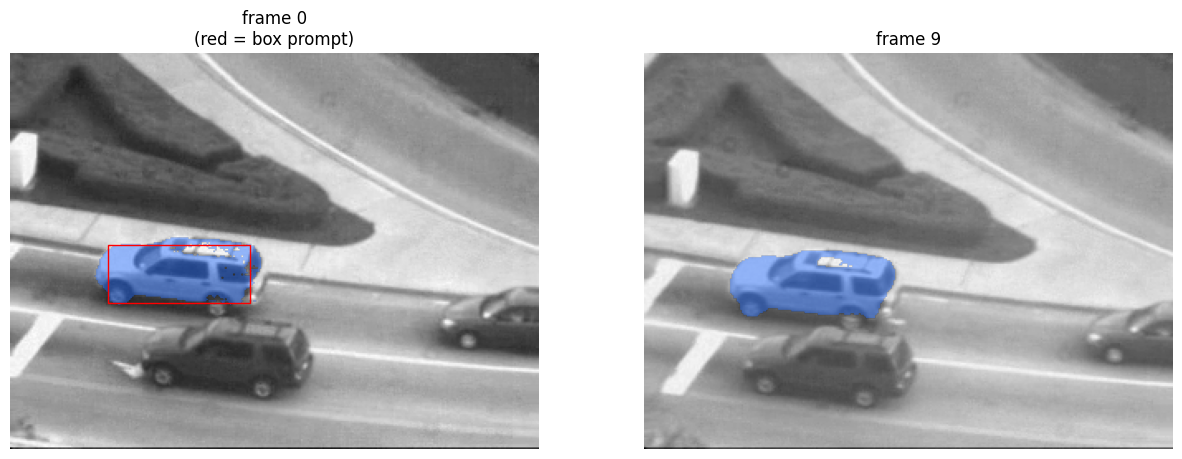

In [7]:
seq = np.load('/content/carseq.npy')
rect = [59, 116, 145, 151]

seq_small = seq[:, :, :10]
masks_dbg = TrackSequenceSAM(seq_small, rect, model, processor)
print('mask shape:', masks_dbg.shape, ' dtype:', masks_dbg.dtype)
print('mask pixels in frame 0:', masks_dbg[0].sum(), ' in frame 9:', masks_dbg[9].sum())

visualize_masks(seq_small, masks_dbg, [0, 9], prompt_rect=rect)

### Q6.2 (a) - Track Car Sequence

Run the following snippet. You should see the mask following the car in the same five frames as in Q2.3. The runtime is printed too; compare it with how long your LK tracker took in Q2.3.

100%|██████████| 415/415 [03:19<00:00,  2.08it/s]


SAM 2 on carseq: 415 frames in 199.2 s (2.1 frames/s)


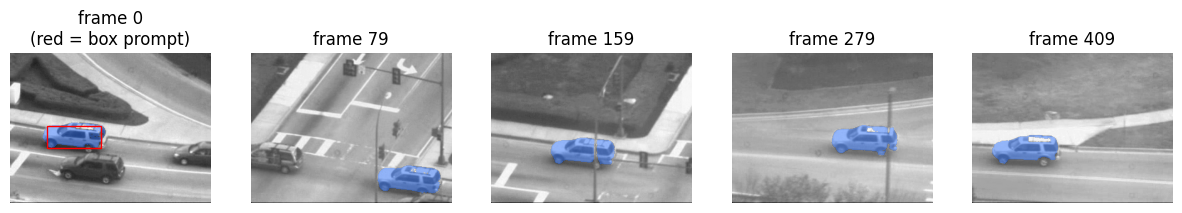

In [8]:
seq_car = np.load('/content/carseq.npy')
rect_car = [59, 116, 145, 151]

t0 = time.time()
masks_sam_car = TrackSequenceSAM(seq_car, rect_car, model, processor)
time_sam_car = time.time() - t0
print(f'SAM 2 on carseq: {seq_car.shape[2]} frames in {time_sam_car:.1f} s '
      f'({seq_car.shape[2] / time_sam_car:.1f} frames/s)')

visualize_masks(seq_car, masks_sam_car, [0, 79, 159, 279, 409], prompt_rect=rect_car)

### Q6.2 (b) - Track Girl Sequence

Same as the car sequence.

100%|██████████| 90/90 [00:43<00:00,  2.07it/s]


SAM 2 on girlseq: 90 frames in 43.4 s (2.1 frames/s)


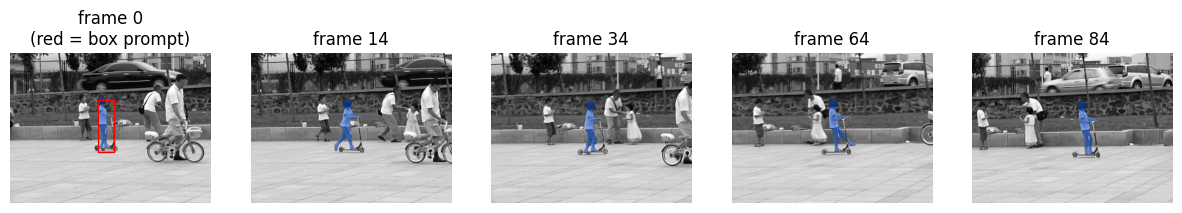

In [9]:
seq_girl = np.load('/content/girlseq.npy')
rect_girl = [280, 152, 330, 318]

t0 = time.time()
masks_sam_girl = TrackSequenceSAM(seq_girl, rect_girl, model, processor)
time_sam_girl = time.time() - t0
print(f'SAM 2 on girlseq: {seq_girl.shape[2]} frames in {time_sam_girl:.1f} s '
      f'({seq_girl.shape[2] / time_sam_girl:.1f} frames/s)')

visualize_masks(seq_girl, masks_sam_girl, [0, 14, 34, 64, 84], prompt_rect=rect_girl)

## Q6.2.1: Does the SAM 2 mask drift like the LK box did in Q2.3? Why or why not, given that SAM 2 only sees the box in frame 0?

===== your answer here! =====

SAM 2 drift less than LK box did in Q2.3. SAM 2 receives the box only in frame 0, but it maintains memory together containing with each new frame to predict the next mask.

===== end of your answer =====